In [1]:
import random
import numpy as np
import torch

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

In [2]:
!pip install biopython

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 45.5 MB/s eta 0:00:00


In [3]:
!wget -c https://stringdb-downloads.org/download/protein.links.v12.0/6239.protein.links.v12.0.txt.gz

--2026-07-12 07:37:33--  https://stringdb-downloads.org/download/protein.links.v12.0/6239.protein.links.v12.0.txt.gz
Resolving stringdb-downloads.org (stringdb-downloads.org)... 49.12.123.75
Connecting to stringdb-downloads.org (stringdb-downloads.org)|49.12.123.75|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 60663523 (58M) [application/octet-stream]
Saving to: ‘6239.protein.links.v12.0.txt.gz’

6239.protein.links. 100%[===================>]  57.85M  16.1MB/s    in 3.7s    

2026-07-12 07:37:38 (15.5 MB/s) - ‘6239.protein.links.v12.0.txt.gz’ saved [60663523/60663523]



In [4]:
import gzip
import shutil

with gzip.open("6239.protein.links.v12.0.txt.gz", "rb") as f_in:
    with open("6239.protein.links.v12.0.txt", "wb") as f_out:
        shutil.copyfileobj(f_in, f_out)

print("Interaction file extracted successfully.")

Interaction file extracted successfully.


In [5]:
import pandas as pd

df = pd.read_csv(
    "6239.protein.links.v12.0.txt",
    sep=r"\s+")
df["protein1"] = df["protein1"].str.replace("6239.", "", regex=False)
df["protein2"] = df["protein2"].str.replace("6239.", "", regex=False)
df = df[df["combined_score"] >= 400]

df["label"] = (df["combined_score"] >= 700).astype(int)

In [6]:
proteins = list(set(df["protein1"]).union(set(df["protein2"])))

existing_edges = {
    tuple(sorted((a, b)))
    for a, b in zip(df["protein1"], df["protein2"])
}

pos_df = df[df["label"] == 1][["protein1", "protein2", "label"]]

negative_pairs = set()

while len(negative_pairs) < len(pos_df):

    a, b = random.sample(proteins, 2)

    pair = tuple(sorted((a, b)))

    if pair in existing_edges:
        continue

    negative_pairs.add(pair)

neg_df = pd.DataFrame(
    list(negative_pairs),
    columns=["protein1", "protein2"]
)

neg_df["label"] = 0

final_df = pd.concat(
    [pos_df, neg_df],
    ignore_index=True
).sample(frac=1, random_state=SEED).reset_index(drop=True)

In [7]:
final_df[["protein1","protein2"]] = (
    final_df.apply(
        lambda x: sorted([x["protein1"], x["protein2"]]),
        axis=1,
        result_type="expand"
    )
)

final_df = final_df.drop_duplicates(
    subset=["protein1","protein2"]
).reset_index(drop=True)

In [8]:
with open("6239.protein.links.v12.0.txt", "r") as f:
    for i in range(5):
        print(f.readline())

protein1 protein2 combined_score

6239.2L52.1a.1 6239.B0205.7.1 161

6239.2L52.1a.1 6239.C24D10.6.1 220

6239.2L52.1a.1 6239.C43E11.3a.1 185

6239.2L52.1a.1 6239.R13F6.5.1 167



In [9]:
!wget -c https://stringdb-downloads.org/download/protein.sequences.v12.0/6239.protein.sequences.v12.0.fa.gz

--2026-07-12 07:38:20--  https://stringdb-downloads.org/download/protein.sequences.v12.0/6239.protein.sequences.v12.0.fa.gz
Resolving stringdb-downloads.org (stringdb-downloads.org)... 49.12.123.75
Connecting to stringdb-downloads.org (stringdb-downloads.org)|49.12.123.75|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 4990858 (4.8M) [application/octet-stream]
Saving to: ‘6239.protein.sequences.v12.0.fa.gz’

6239.protein.sequen 100%[===================>]   4.76M  3.47MB/s    in 1.4s    

2026-07-12 07:38:22 (3.47 MB/s) - ‘6239.protein.sequences.v12.0.fa.gz’ saved [4990858/4990858]



In [10]:
import gzip
import shutil

with gzip.open("6239.protein.sequences.v12.0.fa.gz", "rb") as f_in:
    with open("6239.protein.sequences.v12.0.fa", "wb") as f_out:
        shutil.copyfileobj(f_in, f_out)

In [11]:
from Bio import SeqIO

protein_sequences = {}

for record in SeqIO.parse("6239.protein.sequences.v12.0.fa", "fasta"):
    protein_sequences[record.id.replace("6239.", "")] = str(record.seq)

proteins = list(protein_sequences.keys())

unique_proteins = pd.DataFrame({
    "protein": proteins,
    "sequence": [protein_sequences[p] for p in proteins]
})

In [12]:
unique_proteins.to_csv(
    "elegans_unique_proteins.csv",
    index=False
)

In [13]:
!pip install fair-esm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 93.1/93.1 kB 9.6 MB/s eta 0:00:00


In [14]:

import esm
import torch

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

model, alphabet = (
    esm.pretrained.esm2_t6_8M_UR50D()
)

model = model.to(device)

model.eval()

batch_converter = (
    alphabet.get_batch_converter()
)

print(device)

Downloading: "https://dl.fbaipublicfiles.com/fair-esm/models/esm2_t6_8M_UR50D.pt" to /root/.cache/torch/hub/checkpoints/esm2_t6_8M_UR50D.pt
Downloading: "https://dl.fbaipublicfiles.com/fair-esm/regression/esm2_t6_8M_UR50D-contact-regression.pt" to /root/.cache/torch/hub/checkpoints/esm2_t6_8M_UR50D-contact-regression.pt
cuda


In [15]:
import numpy as np

@torch.no_grad()
def get_embedding(sequence):

    sequence = sequence[:1022]

    data = [
        (
            "protein",
            sequence
        )
    ]

    _, _, tokens = (
        batch_converter(data)
    )

    tokens = tokens.to(device)

    results = model(
        tokens,
        repr_layers=[6],
        return_contacts=False
    )

    token_embeddings = (
        results["representations"][6]
    )

    embedding = (
        token_embeddings[0,1:-1]
        .mean(0)
    )

    return embedding.cpu().numpy()

In [16]:
from tqdm import tqdm

protein_embeddings = {}

for _, row in tqdm(
    unique_proteins.iterrows(),
    total=len(unique_proteins)
):

    protein_id = row["protein"]

    sequence = row["sequence"]

    protein_embeddings[
        protein_id
    ] = get_embedding(
        sequence
    )

print(
    len(protein_embeddings)
)

100%|██████████| 20177/20177 [04:44<00:00, 70.83it/s]

20177


In [17]:
print(len(protein_embeddings))

20177


In [18]:

from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    final_df,
    test_size=0.2,
    stratify=final_df["label"],
    random_state=SEED
)

valid_df, test_df = train_test_split(
    temp_df,
    test_size=0.5,
    stratify=temp_df["label"],
    random_state=SEED
)
valid_proteins = set(
    protein_embeddings.keys()
)
print(train_df.shape)
print(valid_df.shape)
print(test_df.shape)

(257733, 3)
(32217, 3)
(32217, 3)


In [19]:
def pair_set(df):
    return set(
        tuple(sorted((a,b)))
        for a,b in zip(df.protein1, df.protein2)
    )

train_pairs = pair_set(train_df)
valid_pairs = pair_set(valid_df)
test_pairs = pair_set(test_df)

print("Train ∩ Valid =", len(train_pairs & valid_pairs))
print("Train ∩ Test  =", len(train_pairs & test_pairs))
print("Valid ∩ Test  =", len(valid_pairs & test_pairs))

Train ∩ Valid = 0
Train ∩ Test  = 0
Valid ∩ Test  = 0


In [20]:
train_df = train_df[
    train_df["protein1"].isin(valid_proteins) &
    train_df["protein2"].isin(valid_proteins)
].reset_index(drop=True)

valid_df = valid_df[
    valid_df["protein1"].isin(valid_proteins) &
    valid_df["protein2"].isin(valid_proteins)
].reset_index(drop=True)

test_df = test_df[
    test_df["protein1"].isin(valid_proteins) &
    test_df["protein2"].isin(valid_proteins)
].reset_index(drop=True)

In [21]:
final_df.to_csv(
    "elegans_full_seed42.csv",
    index=False
)

train_df.to_csv(
    "train_elegans_seed42.csv",
    index=False
)

valid_df.to_csv(
    "valid_elegans_seed42.csv",
    index=False
)

test_df.to_csv(
    "test_elegans_seed42.csv",
    index=False
)

In [22]:
import numpy as np
import torch

proteins = list(
    protein_embeddings.keys()
)

protein_to_idx = {
    p:i
    for i,p in enumerate(proteins)
}

X = np.array(
    [protein_embeddings[p]
     for p in proteins],
    dtype=np.float32
)

x = torch.tensor(X)

print(x.shape)

torch.Size([20177, 320])


In [23]:
positive_train = train_df[
    train_df["label"] == 1
]
print(positive_train.shape)

(85911, 3)


In [24]:
from collections import defaultdict

neighbors = defaultdict(set)

for _, row in positive_train.iterrows():

    p1 = row["protein1"]
    p2 = row["protein2"]

    neighbors[p1].add(p2)
    neighbors[p2].add(p1)

print(len(neighbors))

10813


In [25]:
hyperedges = []

for protein in neighbors:

    members = set()

    members.add(protein)

    members.update(
        neighbors[protein]
    )

    hyperedges.append(
        list(members)
    )

print(len(hyperedges))

10813


In [26]:
node_ids = []
edge_ids = []

for edge_id, members in enumerate(hyperedges):

    for protein in members:

        if protein in protein_to_idx:

            node_ids.append(
                protein_to_idx[protein]
            )

            edge_ids.append(
                edge_id
            )

hyperedge_index = torch.tensor(
    [node_ids, edge_ids],
    dtype=torch.long
)

print(hyperedge_index.shape)

torch.Size([2, 182635])


In [27]:
!pip install torch-geometric
!pip install tqdm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 37.6 MB/s eta 0:00:00


In [28]:
from torch_geometric.data import Data

graph = Data(
    x=x,
    hyperedge_index=hyperedge_index
)

print(graph)

Data(x=[20177, 320], hyperedge_index=[2, 182635])


In [29]:
graph = graph.to(device)

print(graph.x.device)
print(graph.hyperedge_index.device)

cuda:0
cuda:0


In [30]:
train_pairs = []

for _, row in train_df.iterrows():

    train_pairs.append(
        (
            protein_to_idx[row["protein1"]],
            protein_to_idx[row["protein2"]],
            row["label"]
        )
    )

valid_pairs = []

for _, row in valid_df.iterrows():

    valid_pairs.append(
        (
            protein_to_idx[row["protein1"]],
            protein_to_idx[row["protein2"]],
            row["label"]
        )
    )

test_pairs = []

for _, row in test_df.iterrows():

    test_pairs.append(
        (
            protein_to_idx[row["protein1"]],
            protein_to_idx[row["protein2"]],
            row["label"]
        )
    )

print(len(train_pairs))
print(len(valid_pairs))
print(len(test_pairs))

257733
32217
32217


In [31]:
from torch.utils.data import Dataset

class PPIDataset(Dataset):

    def __init__(self,data):

        self.data=data

    def __len__(self):

        return len(self.data)

    def __getitem__(self,idx):

        p1,p2,y=self.data[idx]

        return (

            torch.tensor(p1),

            torch.tensor(p2),

            torch.tensor(y,dtype=torch.float32)

        )

In [32]:
from torch.utils.data import DataLoader

train_dataset = PPIDataset(
    train_pairs
)

valid_dataset = PPIDataset(
    valid_pairs
)

test_dataset = PPIDataset(
    test_pairs
)

train_loader = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=128,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=128,
    shuffle=False
)

In [33]:
from torch_geometric.nn import HypergraphConv
import torch.nn as nn
import torch.nn.functional as F

class HGNNEncoder(nn.Module):

    def __init__(self):

        super().__init__()

        self.protein_encoder = nn.Sequential(

            nn.Linear(320, 512),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(512, 320)

        )

        self.h1 = HypergraphConv(
            320,
            512
        )

        self.h2 = HypergraphConv(
            512,
            256
        )

        self.h3 = HypergraphConv(
            256,
            128
        )

    def forward(
        self,
        x,
        hyperedge_index
    ):

        residual = x

        x = self.protein_encoder(x)

        x = x + residual

        x = self.h1(
            x,
            hyperedge_index
        )

        x = F.relu(x)

        x = self.h2(
            x,
            hyperedge_index
        )

        x = F.relu(x)

        x = self.h3(
            x,
            hyperedge_index
        )

        return x

In [34]:
class TrainableHGNNPPI(nn.Module):

    def __init__(self):

        super().__init__()

        self.hgnn = HGNNEncoder()

        self.input_proj = nn.Linear(
            448,
            256
        )

        self.attention = nn.MultiheadAttention(
            embed_dim=256,
            num_heads=8,
            batch_first=True
        )



        self.classifier = nn.Sequential(

            nn.Linear(
                1024,
                512
            ),

            nn.ReLU(),

            nn.Dropout(0.3),

            nn.Linear(
                512,
                128
            ),

            nn.ReLU(),

            nn.Dropout(0.3),

            nn.Linear(
                128,
                1
            )
        )

    def forward(
        self,
        p1_idx,
        p2_idx,
        graph_x,
        hyperedge_index
    ):

        hgnn_emb = self.hgnn(
            graph_x,
            hyperedge_index
        )

        final_emb = torch.cat(
            [graph_x, hgnn_emb],
            dim=1
        )

        p1 = final_emb[p1_idx]
        p2 = final_emb[p2_idx]

        p1 = self.input_proj(p1)
        p2 = self.input_proj(p2)

        attn_out, _ = self.attention(
            p1.unsqueeze(1),
            p2.unsqueeze(1),
            p2.unsqueeze(1)
        )

        attn_out = attn_out.squeeze(1)



        features = torch.cat([
            p1,
            p2,
            torch.abs(p1-p2),
            attn_out
        ], dim=1)

        return self.classifier(
            features
        ).squeeze()

In [35]:
device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

model = TrainableHGNNPPI().to(device)

criterion = nn.BCEWithLogitsLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-3
)

print(device)

cuda


In [36]:
!pip install thop

In [37]:
from sklearn.metrics import roc_auc_score
from tqdm import tqdm
import torch

best_auc = 0
counter = 0

EPOCHS = 20

for epoch in range(EPOCHS):

    model.train()

    total_loss = 0

    for p1, p2, y in tqdm(train_loader):

        p1 = p1.to(device)
        p2 = p2.to(device)
        y = y.to(device)

        optimizer.zero_grad()

        logits = model(
            p1,
            p2,
            graph.x,
            graph.hyperedge_index
        )

        loss = criterion(
            logits,
            y
        )

        loss.backward()

        optimizer.step()

        total_loss += loss.item()

    print(
        f"Epoch {epoch+1}",
        total_loss / len(train_loader)
    )

    model.eval()

    valid_probs = []
    valid_labels = []

    with torch.no_grad():

        for p1, p2, y in valid_loader:

            p1 = p1.to(device)
            p2 = p2.to(device)

            logits = model(
                p1,
                p2,
                graph.x,
                graph.hyperedge_index
            )

            prob = torch.sigmoid(
                logits
            )

            valid_probs.extend(
                prob.cpu().numpy()
            )

            valid_labels.extend(
                y.numpy()
            )

    valid_auc = roc_auc_score(
        valid_labels,
        valid_probs
    )

    print(
        "Validation AUC:",
        valid_auc
    )

    if valid_auc > best_auc:

        best_auc = valid_auc

        torch.save(
    model.state_dict(),
    "best_model_elegans.pth"
)

        counter = 0

        print(
            "New best model saved"
        )

    else:

        counter += 1

        if counter >= 5:

            print(
                "Early stopping"
            )

            break

print(
    "Best Validation AUC:",
    best_auc
)
model.load_state_dict(
    torch.load("best_model_elegans.pth")
)
from thop import profile

p1, p2, _ = next(iter(test_loader))

p1 = p1.to(device)
p2 = p2.to(device)

flops, params = profile(
    model,
    inputs=(p1, p2, graph.x, graph.hyperedge_index),
    verbose=False
)

print("="*50)
print("MODEL COMPUTATIONAL COMPLEXITY")
print("="*50)
print(f"FLOPs      : {flops:,}")
print(f"Parameters : {params:,}")

100%|██████████| 2014/2014 [03:07<00:00, 10.74it/s]


Epoch 1 0.1436946807223878
Validation AUC: 0.9729533368247079
New best model saved


100%|██████████| 2014/2014 [03:04<00:00, 10.94it/s]


Epoch 2 0.10218427624357374
Validation AUC: 0.9758515462425031
New best model saved


100%|██████████| 2014/2014 [03:03<00:00, 10.96it/s]


Epoch 3 0.09029846727596494
Validation AUC: 0.9769528990747899
New best model saved


... (30 outputs left out)

100%|██████████| 2014/2014 [03:02<00:00, 11.04it/s]


Epoch 19 0.0413440931124831
Validation AUC: 0.9797200432155349


100%|██████████| 2014/2014 [03:02<00:00, 11.06it/s]


Epoch 20 0.03971274561549758
Validation AUC: 0.979856670979162
Best Validation AUC: 0.9799662363568095
MODEL COMPUTATIONAL COMPLEXITY
FLOPs      : 6,716,473,344.0
Parameters : 1,034,049.0


In [38]:
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    f1_score,
    precision_score,
    recall_score,
    matthews_corrcoef,
    average_precision_score,
    confusion_matrix
)

model.eval()

preds = []
probs = []
labels = []

with torch.no_grad():

    for p1, p2, y in test_loader:

        p1 = p1.to(device)
        p2 = p2.to(device)

        logits = model(
            p1,
            p2,
            graph.x,
            graph.hyperedge_index
        )

        prob = torch.sigmoid(
            logits
        )

        pred = (
            prob > 0.5
        ).int()

        probs.extend(
            prob.cpu().numpy()
        )

        preds.extend(
            pred.cpu().numpy()
        )

        labels.extend(
            y.numpy()
        )

acc = accuracy_score(
    labels,
    preds
)

auc = roc_auc_score(
    labels,
    probs
)

f1 = f1_score(
    labels,
    preds
)

precision = precision_score(
    labels,
    preds
)

recall = recall_score(
    labels,
    preds
)

mcc = matthews_corrcoef(
    labels,
    preds
)

aupr = average_precision_score(
    labels,
    probs
)

cm = confusion_matrix(
    labels,
    preds
)

print("Accuracy :", acc)
print("AUC      :", auc)
print("AUPR     :", aupr)
print("F1       :", f1)
print("Precision:", precision)
print("Recall   :", recall)
print("MCC      :", mcc)
print(cm)

Accuracy : 0.9572585901853059
AUC      : 0.9809809479328625
AUPR     : 0.9770081698288221
F1       : 0.9331066310420209
Precision: 0.9754214909607962
Recall   : 0.894310457212031
MCC      : 0.9036247836363729
[[21236   242]
 [ 1135  9604]]


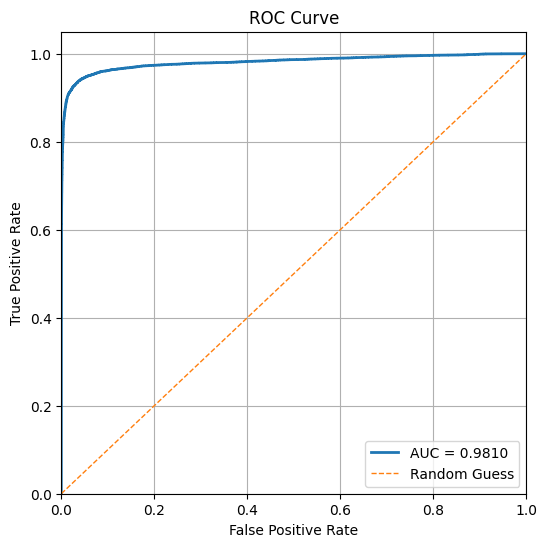

In [39]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt
fpr, tpr, thresholds = roc_curve(
    labels,
    probs
)
plt.figure(figsize=(6,6))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"AUC = {auc:.4f}"
)

plt.plot(
    [0,1],
    [0,1],
    linestyle="--",
    linewidth=1,
    label="Random Guess"
)

plt.xlim([0.0,1.0])
plt.ylim([0.0,1.05])

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")

plt.legend(loc="lower right")

plt.grid(True)

plt.savefig(
    "ROC_Curve_elegans.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()